# Same Kendall τ, different joint extremes

## tl;dr
Known-parameter Gaussian and Student-t copulas can have equal Kendall τ and different joint exceedance probabilities. Finite-threshold L(q) is not its asymptotic limit. This executed audit compares two quadratures and direct versus conditional Monte Carlo. All measured values below come from saved reproducible raw evidence, not forecasts.

## Context & Methods
### Key Assumptions
Bivariate IID elliptical distributions, known ρ, ν and marginal tail probability p=1−q. τ=2 arcsin(ρ)/π; L(q)=P(U>q,V>q)/(1−q). The Gaussian λ∞=0 for |ρ|<1; the t coefficient depends on ν as well as ρ. Equal rank correlation is not full model identification.

### 1. Load the preregistered configuration

In [1]:
import csv, json
from pathlib import Path
import numpy as np
from IPython.display import display, Image
from src.copulas import Copula, kendall_tau, asymptotic_lambda, direct, conditional
from src.reference import tail_coordinate_reference, conditional_second_moment
config=json.loads(Path('config.json').read_text())
result=json.loads(Path('benchmarks/results.json').read_text())
print(config['question'])
print(json.dumps(result['checks'],indent=2))
assert all(result['passed'].values())

Does matching Kendall tau suffice for joint extremes, and does conditional Monte Carlo resolve finite-threshold coexceedance more precisely than direct simulation?
{
  "max_quadrature_disagreement": 3.993009983532976e-11,
  "max_independence_error": 9.71445146547012e-17,
  "max_empirical_kendall_error": 0.006670627062706214,
  "min_t4_to_gaussian_joint_ratio": 4.856196277246979,
  "max_conditional_to_direct_rmse_ratio": 0.008863733701078102,
  "max_conditional_relative_rmse": 0.0034776536357575827,
  "max_variance_bound_violation": 0.0
}


### 2. Verify matching rank dependence and different limits
The t sampler uses one shared chi-square scale. At ρ=0, t components are uncorrelated but not independent; the Gaussian comparison is independent.

In [2]:
for rho in (0.,.5):
    for df in (None,4.,30.):
        model=Copula(rho,df)
        print(f'rho={rho}, df={df}: tau={kendall_tau(model):.6f}; lambda_infinity={asymptotic_lambda(model):.6f}')

rho=0.0, df=None: tau=0.000000; lambda_infinity=0.000000
rho=0.0, df=4.0: tau=0.000000; lambda_infinity=0.075587
rho=0.0, df=30.0: tau=0.000000; lambda_infinity=0.000004
rho=0.5, df=None: tau=0.333333; lambda_infinity=0.000000
rho=0.5, df=4.0: tau=0.333333; lambda_infinity=0.253170
rho=0.5, df=30.0: tau=0.333333; lambda_infinity=0.003047


## Data
48 deterministic scenarios; 1,280 timed Monte Carlo runs from 80 independent replicates per cell. N=2,000 and 20,000; q=.99 and .999; ρ=.5; Gaussian/t4. No fitting on the evaluation samples. Raw seeds and counts: benchmarks/raw.csv. Numerical references: population.csv; resource peaks: memory.csv.

### 3. Read finite-threshold coexceedance, not just λ∞

In [3]:
with open('benchmarks/population.csv') as f:
    population=list(csv.DictReader(f))
for row in population:
    if row['rho']=='0.5' and row['q'] in ('0.99','0.999','0.9999'):
        print(row['model'], 'q='+row['q'], 'joint='+format(float(row['joint_probability']),'.8g'), 'L(q)='+format(float(row['finite_lambda']),'.6f'), 'limit='+format(float(row['asymptotic_lambda']),'.6f'))

gaussian q=0.99 joint=0.0012939244 L(q)=0.129392 limit=0.000000
gaussian q=0.999 joint=5.4259168e-05 L(q)=0.054259 limit=0.000000
gaussian q=0.9999 joint=2.3311437e-06 L(q)=0.023311 limit=0.000000
t4 q=0.99 joint=0.0028767843 L(q)=0.287678 limit=0.253170
t4 q=0.999 joint=0.00026349317 L(q)=0.263493 limit=0.253170
t4 q=0.9999 joint=2.5637851e-05 L(q)=0.256379 limit=0.253170
t30 q=0.99 joint=0.0015196546 L(q)=0.151965 limit=0.003047
t30 q=0.999 joint=8.1110105e-05 L(q)=0.081110 limit=0.003047
t30 q=0.9999 joint=4.8471928e-06 L(q)=0.048472 limit=0.003047


### 4. Recompute the variance-bound proposition
For D=1(A∩B)/p, Var(D)=L/p−L². For H=P(B|X), X∼X|A, E[H]=L and 0≤H≤1 imply Var(H)≤L(1−L). Thus Var(H)/Var(D)≤p(1−L)/(1−pL)≤p. This known conditioning argument assumes the conditional law and p are known. It is a sample-efficiency bound, not a CPU-time guarantee.

In [4]:
model=Copula(.5,4.)
q=.999
lam,_=tail_coordinate_reference(model,q)
second=conditional_second_moment(model,q)
ratio=(second-lam*lam)/(lam/(1-q)-lam*lam)
bound=(1-q)*(1-lam)/(1-(1-q)*lam)
print({'finite_lambda':lam,'variance_ratio':ratio,'bound':bound})
assert ratio<=bound+1e-10

{'finite_lambda': 0.2634931705929513, 'variance_ratio': 6.156797010330491e-05, 'bound': 0.0007367009450748459}


## Results
### 5. Inspect empirical accuracy, cost and zero-event failures
RMSE is computed across all 80 replicates against the finite-q quadrature. The direct estimator is not biased downward merely because individual runs return zero. Replicate quantiles are dispersion, not confidence intervals.

In [5]:
with open('benchmarks/summary.csv') as f:
    summary=list(csv.DictReader(f))
for row in summary:
    if row['model']=='t4' and row['q']=='0.999':
        print({k:row[k] for k in ('n','method','relative_rmse','mean_seconds','zero_joint_fraction','undefined_random_denominator','time_times_mse_proxy')})

{'n': '2000', 'method': 'conditional', 'relative_rmse': '0.010232170669176833', 'mean_seconds': '0.0011540365125000563', 'zero_joint_fraction': '', 'undefined_random_denominator': '', 'time_times_mse_proxy': '8.388683850136547e-09'}
{'n': '2000', 'method': 'direct', 'relative_rmse': '1.4406673955446498', 'mean_seconds': '0.0002753556875063623', 'zero_joint_fraction': '0.65', 'undefined_random_denominator': '14', 'time_times_mse_proxy': '3.9678955657812164e-05'}
{'n': '20000', 'method': 'conditional', 'relative_rmse': '0.0034776536357575827', 'mean_seconds': '0.007385466662510965', 'zero_joint_fraction': '', 'undefined_random_denominator': '', 'time_times_mse_proxy': '6.201393924825143e-09'}
{'n': '20000', 'method': 'direct', 'relative_rmse': '0.39234635798394907', 'mean_seconds': '0.0013913511374994414', 'zero_joint_fraction': '0.0125', 'undefined_random_denominator': '0', 'time_times_mse_proxy': '1.4870128627112996e-05'}


### 6. Recompute one independent illustration
This is an extra illustrative draw, not a replacement for the full replication benchmark. N is equal, but inverse-quantile and conditional-CDF costs differ.

In [6]:
for name,method,seed in [('direct',direct,1801),('conditional',conditional,1802)]:
    estimate=method(Copula(.5,4.),.999,20000,np.random.default_rng(seed))
    print(name,estimate)

direct {'estimate': 0.19999999999999982, 'joint_count': 4, 'marginal_count': 17, 'random_denominator_estimate': 0.23529411764705882}
conditional {'estimate': 0.26378054989707783, 'sample_se': 0.0009038288433408478}


### 7. Inspect the summary figure
Left: finite-q quadrature versus dashed limits. Right: observed RMSE at equal N, not equal runtime.

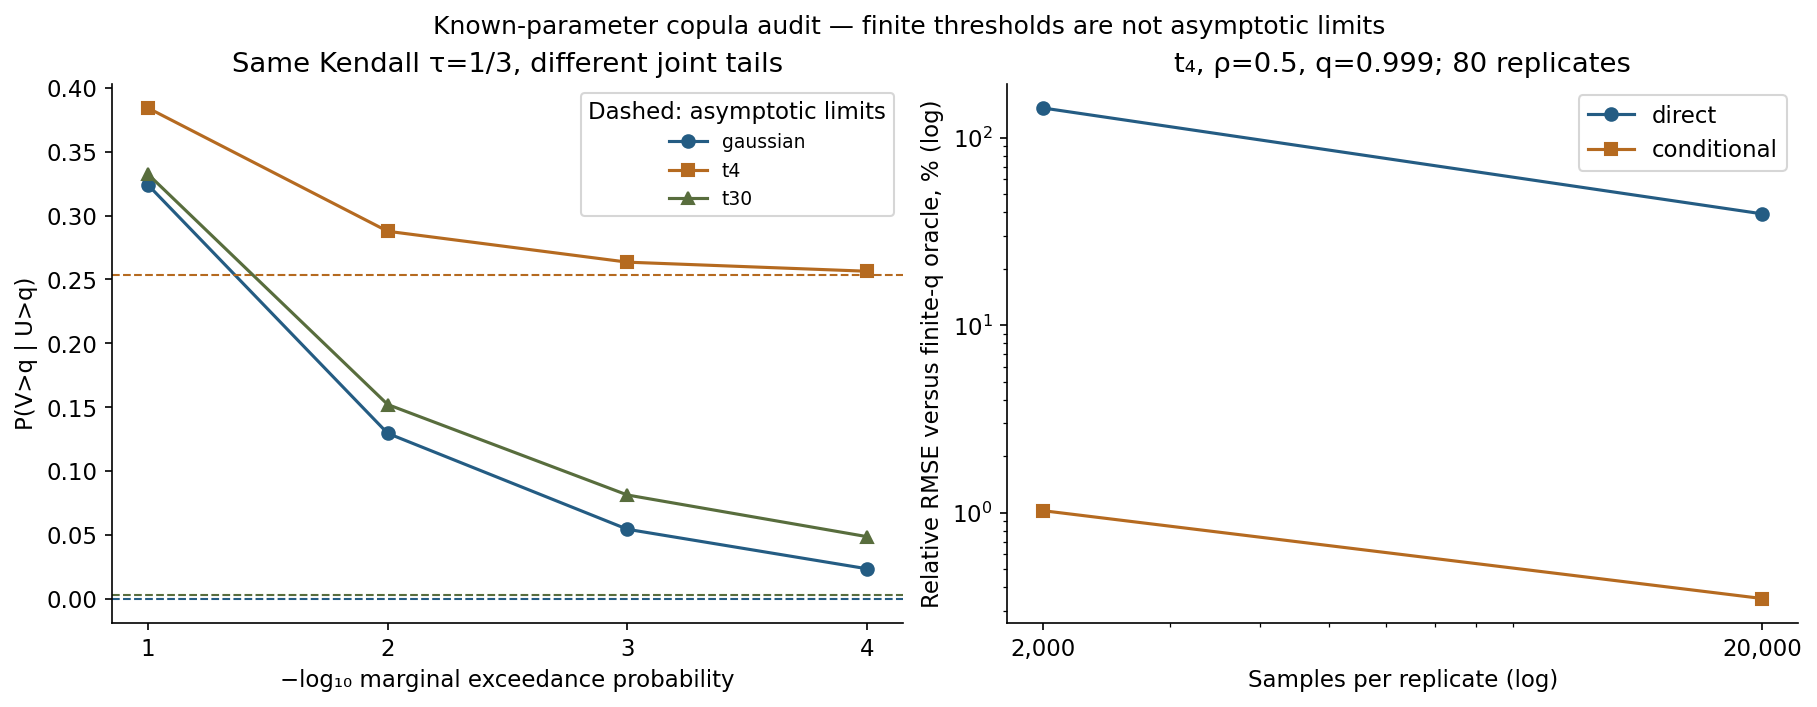

In [7]:
display(Image(filename='benchmarks/audit.png'))

### 8. Check sampler rank diagnostics and numerical residuals

In [8]:
with open('benchmarks/rank_check.csv') as f:
    print(list(csv.DictReader(f)))
print('max quadrature disagreement:',result['checks']['max_quadrature_disagreement'])
print('All gates passed:', all(result['passed'].values()))

[{'model': 'gaussian', 'rho': '0.5', 'df': '', 'n': '10000', 'seed': '180041', 'population_tau': '0.33333333333333337', 'empirical_tau': '0.33689228922892284'}, {'model': 't4', 'rho': '0.5', 'df': '4.0', 'n': '10000', 'seed': '180042', 'population_tau': '0.33333333333333337', 'empirical_tau': '0.3400039603960396'}, {'model': 't30', 'rho': '0.5', 'df': '30.0', 'n': '10000', 'seed': '180043', 'population_tau': '0.33333333333333337', 'empirical_tau': '0.3283407940794079'}]
max quadrature disagreement: 3.993009983532976e-11
All gates passed: True


## Takeaways
Matching central rank dependence does not identify joint tail behavior. Gaussian asymptotic independence is not finite-threshold independence; a t limit is also not an exact finite-q probability. Conditioning improves precision in the declared synthetic experiment, at a different per-sample cost.

Limits: known parameters, symmetric families, no temporal dependence, no calibration of estimated copulas, no coverage study and no financial capital validation. The two quadratures share SciPy; agreement is not formal certification. See informe.md, config.json and referencias.bib for the derivation, raw negative outcomes, references and scope.